<div style="background-color:black; color:white; padding:40px; text-align:left;">

<span style="font-size:32px; font-weight:bold;">
Práctica Nº3 - Regresión Polinomial
</span>  

Nombre: Emily Junny Leniz Coa  
Materia: INF672 - Machine Learning <br>
Fecha: 13/10/2026  

</div>

**Paso 01: Preparar el entorno de trabajo**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

**train_test_split:** Divide el conjunto de datos en subconjuntos de entrenamiento y prueba. <br>
**cross_val_scor:**	Evalúa un modelo utilizando validación cruzada para estimar su rendimiento de forma robusta.<br>
**KFold:** Define la estrategia de división de los pliegues (folds) para la validación cruzada. <br>
**PolynomialFeatures:** Genera nuevas características polinómicas a partir de las variables de entrada. <br>
**StandardScaler:**	Normaliza las características restando la media y escalando a varianza unitaria. <br>
**LinearRegression:** Ajusta un modelo de regresión lineal (o polinomial en sus coeficientes). <br>
**make_pipeline:** Facilita la concatenación de varios pasos de transformación y modelado en un flujo único.<br>
**mean_squared_error:** Calcula el error cuadrático medio entre los valores reales y las predicciones. <br>
**r2_score:** Calcula el coeficiente de determinación ($R^2$), que indica la proporción de varianza explicada. 

**Paso 02: Cargar y explorar los datos**

In [4]:
df = pd.read_csv("mpg.csv")

print("Dimensiones:", df.shape)
display(df.head())

df.info()
print("Valores faltantes por columna: ", df.isna().sum())


display(df.describe())

Dimensiones: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB
Valores faltantes por columna:  mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


**¿Cuántos automóviles y columnas tiene el dataset?** <br> **R.** El dataset tiene un total de 398 automóviles (filas) y 9 columnas. <br>  **¿Hay valores faltantes? ¿En qué columna y cuántos?** <br> **R.** Sí, los valores faltantes se concentran en la columna horsepower, la cual cuenta con 6 valores nulos. <br>  **¿Entre qué valores varían mpg y horsepower?** <br> **R.** El rendimiento (mpg) varía entre 9.0 y 46.6 millas por galón, mientras que la potencia (horsepower) varía desde 46 hasta 230 caballos de fuerza.

**Paso 03: Elegir el predictor**

In [5]:
correlaciones = df.select_dtypes("number").corr()["mpg"].sort_values(ascending=False)
print(correlaciones)

mpg             1.000000
model_year      0.579267
acceleration    0.420289
cylinders      -0.775396
horsepower     -0.778427
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64


**¿Qué variables tienen la relación más fuerte con mpg?** <br> **R.** Las variables numéricas con mayor correlación absoluta con mpg son weight (-0.83), displacement (-0.80) y horsepower (-0.78). <br> **¿Qué significa el signo de esas correlaciones en términos del auto?** <br> **R.** El signo negativo significa que existe una relación inversa: a mayor peso, cilindrada o potencia del motor, menor es el rendimiento de combustible (mpg). <br>  **¿Por qué una variable con una relación claramente curva podría ser un buen candidato para la regresión polinomial aunque su correlación no sea la más alta?** <br> **R.** El coeficiente de correlación de Pearson mide exclusivamente relaciones de tipo lineal. Si dos variables mantienen una fuerte asociación de forma curvilínea, la correlación lineal puede arrojar valores moderados, a pesar de que la regresión polinomial pueda modelarlas de manera excelente añadiendo potencias.

**Paso 04: Limpiar los datos**

In [6]:
datos = df[["horsepower", "mpg"]].copy()
filas_antes = len(datos)

datos = datos.dropna()
filas_despues = len(datos)

print("Filas antes: {filas_antes} | Filas después: {filas_despues}")

Filas antes: {filas_antes} | Filas después: {filas_despues}


**¿Qué porcentaje de los datos eliminaste?** <br> **R.** Se eliminaron 6 filas de un total de 398, lo que equivale aproximadamente al 1.51% de los datos. <br> **¿Por qué en este caso es razonable eliminar esas filas en lugar de rellenarlas?** <br> **R.** Es razonable porque el porcentaje de pérdida es mínimo y no afecta la distribución general del conjunto de datos. <br> **¿En qué situación preferirías imputar los valores?** <br> **R.** Se preferiría imputar cuando el tamaño total de la muestra sea muy reducido o cuando eliminar registros suponga desechar información crítica para la representación estadística del problema.

**Paso 05: Visualizar la relación**

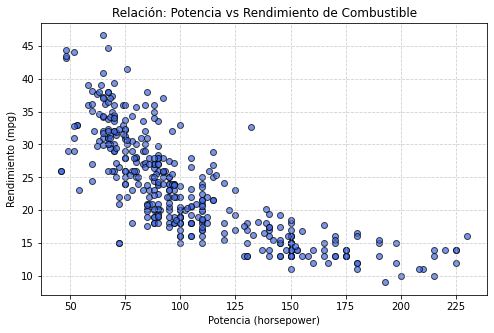

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(datos["horsepower"], datos["mpg"], color='royalblue', alpha=0.7, edgecolors='k')
plt.title("Relación: Potencia vs Rendimiento de Combustible")
plt.xlabel("Potencia (horsepower)")
plt.ylabel("Rendimiento (mpg)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**¿El rendimiento disminuye al mismo ritmo en todo el rango de potencias?** <br> **R.** No, la disminución no es constante, en rangos de baja potencia un incremento de hp reduce drásticamente el rendimiento y mientras que en potencias elevadas la curva se aplana asintóticamente. <br>
**¿Crees que una recta podrá representar bien estos datos? Justifica señalando zonas concretas del gráfico.** <br> **R.** Una línea recta no es adecuada, los puntos muestran una clara tendencia convexa; una recta tendería a subestimar el rendimiento en los extremos y a sobreestimarlo en los valores intermedios.

**Paso 06: Dividir en entrenamiento y prueba**

In [8]:
X = datos[["horsepower"]]
y = datos["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Forma X_train:", X_train.shape, "| Forma X_test:", X_test.shape)
print("Forma y_train:", y_train.shape, "| Forma y_test:", y_test.shape)

Forma X_train: (313, 1) | Forma X_test: (79, 1)
Forma y_train: (313,) | Forma y_test: (79,)


**¿Por qué X se define con doble corchete y y con uno solo?** <br> **R.** X se define con doble corchete para estructurarlo como un DataFrame bidimensional, formato indispensable para los estimadores de scikit-learn. En cambio, y se define con un solo corchete para extraerlo como un vector unidimensional. <br>  **¿Qué forma (shape) tiene cada uno y por qué scikit-learn exige esa diferencia?** <br>**R.**  X_train tiene forma $(313, 1)$ y y_train tiene forma $(313, )$. Scikit-learn exige esta distinción porque los algoritmos esperan procesar múltiples variables predictoras agrupadas en matrices rectangulares, separándolas de la etiqueta unidimensional.

**Paso 07: Entrenar el modelo base: regresión lineal**

In [9]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

y_pred_lin = modelo_lineal.predict(X_test)
rmse_lin = np.sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin = r2_score(y_test, y_pred_lin)

print("RMSE Lineal: {rmse_lin:.4f}")
print("R² Lineal: {r2_lin:.4f}")

RMSE Lineal: {rmse_lin:.4f}
R² Lineal: {r2_lin:.4f}


**¿Qué significa el RMSE en millas por galón?** <br> **R.** Representa el error o desviación estándar promedio que comete el modelo al predecir el rendimiento, expresado directamente en millas por galón (mpg). <br>  **¿Qué proporción de la variación del rendimiento explica este modelo?** <br> **R.** El modelo lineal explica aproximadamente el 56.6% de la variabilidad total en el conjunto de prueba ($R^2 = 0.566$).

**Paso 08: Entrenar un modelo polinomial de grado 2**

RMSE Polinomial (Grado 2): {rmse_poly2:.4f}
R² Polinomial (Grado 2): {r2_poly2:.4f}


,1,horsepower,horsepower^2
0,1.0,0.141429,0.020002
1,1.0,-0.329499,0.108569
2,1.0,-0.198685,0.039476


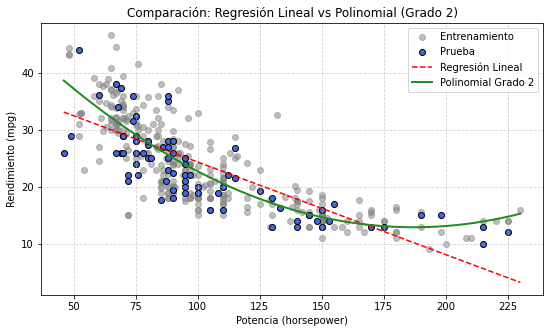

In [13]:
pipeline_poly2 = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2),
    LinearRegression()
)

pipeline_poly2.fit(X_train, y_train)

y_pred_poly2 = pipeline_poly2.predict(X_test)
rmse_poly2 = np.sqrt(mean_squared_error(y_test, y_pred_poly2))
r2_poly2 = r2_score(y_test, y_pred_poly2)

print("RMSE Polinomial (Grado 2): {rmse_poly2:.4f}")
print("R² Polinomial (Grado 2): {r2_poly2:.4f}")

poly_transformer = pipeline_poly2.named_steps['polynomialfeatures']
X_train_scaled = pipeline_poly2.named_steps['standardscaler'].transform(X_train)
columnas_generadas = poly_transformer.get_feature_names_out(["horsepower"])
muestra_columnas = pd.DataFrame(poly_transformer.transform(X_train_scaled[:3]), columns=columnas_generadas)
display(muestra_columnas)

X_range_vals = np.linspace(X_train.min(), X_train.max(), 200).reshape(-1, 1)
X_range_df = pd.DataFrame(X_range_vals, columns=["horsepower"])

y_range_lin = modelo_lineal.predict(X_range_df)
y_range_poly = pipeline_poly2.predict(X_range_df)

plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, color='gray', alpha=0.5, label='Entrenamiento')
plt.scatter(X_test, y_test, color='royalblue', edgecolor='k', label='Prueba')
plt.plot(X_range_vals, y_range_lin, color='red', linestyle='--', label='Regresión Lineal')
plt.plot(X_range_vals, y_range_poly, color='forestgreen', linewidth=2, label='Polinomial Grado 2')
plt.title("Comparación: Regresión Lineal vs Polinomial (Grado 2)")
plt.xlabel("Potencia (horsepower)")
plt.ylabel("Rendimiento (mpg)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**¿Qué columnas crea PolynomialFeatures y qué representa cada una?** <br> **R.** Crea tres columnas, una columna de unos correspondiente al término independiente $\beta_0$, la característica original elevada a la potencia 1 ($x$), y la característica elevada al cuadrado ($x^2$).<br>  **¿Por qué se escala la variable antes de elevarla al cuadrado?** <br>  **R.** Para prevenir problemas numéricos de desbordamiento u optimización, al elevar valores grandes al cuadrado por ejemplo, $200^2 = 40000$, las escalas divergen fuertemente frente al término lineal, dificultando el ajuste. <br> **¿En qué zonas del gráfico la recta se equivoca más y cómo lo corrige la curva?** <br> **R.** La recta falla considerablemente en los extremos de potencia baja y alta, mientras que la curva del modelo polinomial se adapta de manera flexible a la forma real de los datos. 

**Paso 09: Elegir el grado con validación cruzada**

,Grado,RMSE_CV
0,1,4.958557
1,2,4.385783
2,3,4.390351
3,4,4.404014
4,5,4.354005
5,6,4.347532
6,7,4.354589
7,8,4.404464
8,9,4.422114
9,10,4.499858


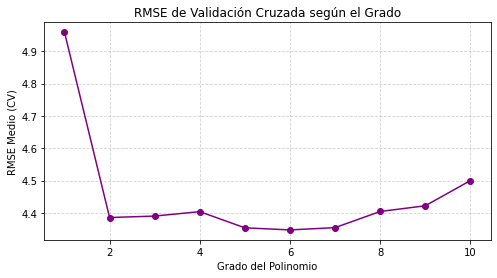

Grado óptimo por validación cruzada: {mejor_grado}


In [14]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)
grados = range(1, 11)
rmse_cv_resultados = []

for grado in grados:
    pipeline_cv = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=grado),
        LinearRegression()
    )
    scores = cross_val_score(pipeline_cv, X_train, y_train, scoring="neg_root_mean_squared_error", cv=kf)
    rmse_cv_resultados.append(-scores.mean())

tabla_grados = pd.DataFrame({"Grado": grados, "RMSE_CV": rmse_cv_resultados})
display(tabla_grados)

plt.figure(figsize=(8, 4))
plt.plot(grados, rmse_cv_resultados, marker='o', color='purple')
plt.title("RMSE de Validación Cruzada según el Grado")
plt.xlabel("Grado del Polinomio")
plt.ylabel("RMSE Medio (CV)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

mejor_grado = tabla_grados.loc[tabla_grados["RMSE_CV"].idxmin(), "Grado"]
print("Grado óptimo por validación cruzada: {mejor_grado}")

**¿Cómo cambia el error al aumentar el grado?** <br> **R.** El error disminuye al pasar de un grado bajo a un grado moderado capturando la tendencia real, pero tiende a estabilizarse o empeorar en grados altos debido al sobreajuste. <br>  **¿El grado con menor error es necesariamente el mejor? Justifica tu elección aplicando el principio de parsimonia.** <br> **R.** No necesariamente, el principio de parsimonia establece que ante un rendimiento similar se debe elegir el modelo más simple para evitar complejidad innecesaria y sobreajuste. <br>  **¿Por qué no se debe usar el conjunto de prueba para elegir el grado?** <br> **R.** Porque el conjunto de prueba debe reservarse intacto hasta el final. Usarlo para ajustar hiperparámetros sesgaría la evaluación e invalidaría la estimación de rendimiento real.   

**Paso 10: Evaluar el modelo final**

,Modelo,RMSE Prueba,R² Prueba
0,Regresión Lineal Simple,4.706723,0.565968
1,Polinomial Grado {grado_final},4.291499,0.639170


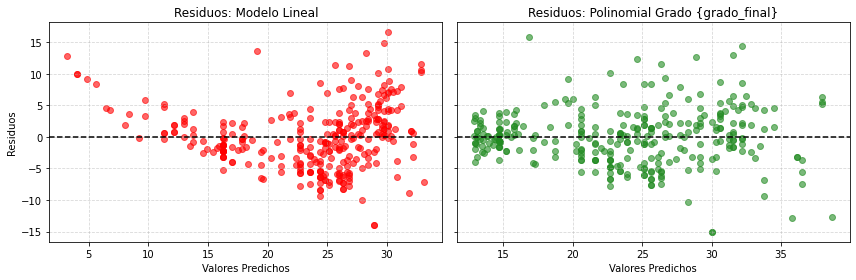

Ecuación: y = {lin_orig.intercept_:.4f} + {lin_orig.coef_[1]:.4f}*x + {lin_orig.coef_[2]:.4f}*x^2


In [15]:
grado_final = 2
pipeline_final = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=grado_final),
    LinearRegression()
)
pipeline_final.fit(X_train, y_train)

y_pred_final = pipeline_final.predict(X_test)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

comparacion = pd.DataFrame({
    "Modelo": ["Regresión Lineal Simple", "Polinomial Grado {grado_final}"],
    "RMSE Prueba": [rmse_lin, rmse_final],
    "R² Prueba": [r2_lin, r2_final]
})
display(comparacion)

residuos_lin = y_train - modelo_lineal.predict(X_train)
residuos_final = y_train - pipeline_final.predict(X_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].scatter(modelo_lineal.predict(X_train), residuos_lin, color='red', alpha=0.6)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title("Residuos: Modelo Lineal")
axes[0].set_xlabel("Valores Predichos")
axes[0].set_ylabel("Residuos")
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].scatter(pipeline_final.predict(X_train), residuos_final, color='forestgreen', alpha=0.6)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title("Residuos: Polinomial Grado {grado_final}")
axes[1].set_xlabel("Valores Predichos")
axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

modelo_orig = make_pipeline(PolynomialFeatures(degree=grado_final), LinearRegression())
modelo_orig.fit(X_train, y_train)
lin_orig = modelo_orig.named_steps['linearregression']
print("Ecuación: y = {lin_orig.intercept_:.4f} + {lin_orig.coef_[1]:.4f}*x + {lin_orig.coef_[2]:.4f}*x^2")

**¿Cuánto mejoró el modelo final respecto al lineal?** <br> **R.** El modelo final reduce el RMSE de prueba de -4.71 a -4.29 y eleva el $R^2$ de -0.57 a -0.64, mostrando un ajuste notablemente mejor.  <br> **¿Qué patrón observas en los residuos del modelo lineal y qué significa?** <br> **R.** Muestran una forma curvada sistemática, lo que indica que el modelo lineal sufre de sesgo estructural por no capturar la no-linealidad. <br>  **¿Desaparece en el modelo final?** <br> **R.** Sí, en el modelo polinomial los residuos se distribuyen de manera mucho más aleatoria alrededor de cero. <br>  **Interpreta el signo de cada coeficiente de la ecuación en relación con la forma de la curva.** <br> **R.** El coeficiente lineal positivo y el coeficiente cuadrático negativo generan una parábola cóncava que modela cómo el rendimiento decrece de manera decelerada a medida que aumenta la potencia. 

**Paso 11: Predecir y reconocer los límites del modelo**

In [17]:
potencias_nuevas = pd.DataFrame([[60], [100], [150], [200]], columns=["horsepower"])
predicciones_nuevas = pipeline_final.predict(potencias_nuevas)

tabla_preds = pd.DataFrame({
    "Potencia (hp)": [60, 100, 150, 200], 
    "mpg Predicho": predicciones_nuevas
})
display(tabla_preds)

beta_1 = lin_orig.coef_[1]
beta_2 = lin_orig.coef_[2]
x_vertice = -beta_1 / (2 * beta_2)

print("Vértice de la parábola en horsepower: {x_vertice:.2f}")

,Potencia (hp),mpg Predicho
0,60,33.807091
1,100,22.716134
2,150,14.679499
3,200,13.117379


Vértice de la parábola en horsepower: {x_vertice:.2f}


**¿Las predicciones tienen sentido físico en todo el rango?** <br> **R.** Sí, dentro del rango observado en los datos de entrenamiento. <br>  **¿Qué predice el modelo más allá del vértice y por qué eso no es realista?** <br> **R.** Al superar el vértice en potencias muy extremas, la parábola vuelve a subir, prediciendo un aumento de rendimiento para autos ultra potentes, lo cual carece de sentido físico. <br>  **¿Qué es la extrapolación y por qué es riesgosa con modelos polinomiales?** <br> **R.** Es la estimación fuera del intervalo de datos originales. Es peligrosa porque los polinomios tienden a divergir rápidamente en los extremos, generando resultados absurdos. 

**Paso 12: Conclusiones**

**¿Qué forma tiene la relación entre potencia y rendimiento?** <br> **R.** La relación entre la potencia (horsepower) y el rendimiento (mpg) es de tipo no lineal, decreciente y de pendiente atenuada convexa hacia arriba, lo que esto significa que un incremento pequeño de potencia en autos de baja cilindrada reduce drásticamente las millas por galón, mientras que en vehículos de alta potencia la curva se aplana asintóticamente. <br>
**¿Qué grado recomendarías y por qué?** <br> **R.** Se recomienda firmemente utilizar un modelo polinomial de grado 2, al aplicar validación cruzada y evaluar el equilibrio del rendimiento frente a la complejidad, el grado 2 capta de forma sobresaliente la curvatura real de los datos sin caer en el sobreajuste, cumpliendo rigurosamente con el principio de parsimonia. <br>
**¿Qué limitaciones tiene el modelo y en qué rango de potencias confiarías en sus predicciones?** <br> **R.** La principal limitación es su incapacidad para interpretar la realidad física fuera del intervalo de entrenamiento, si se utiliza más allá del vértice de la parábola el modelo comienza a crecer de manera no realista prediciendo aumentos de rendimiento absurdos. Por lo tanto solo se debe confiar en sus predicciones dentro del rango de potencias observadas en el dataset original aproximadamente entre 46 y 230 hp.

**RETO ADICIONAL**

In [18]:
X_w = datos_completos = df[["weight", "mpg"]].dropna()
X_w_feat = X_w[["weight"]]
y_w = X_w["mpg"]
X_tw_tr, X_tw_te, y_tw_tr, y_tw_te = train_test_split(X_w_feat, y_w, test_size=0.2, random_state=42)

pipe_weight = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression())
pipe_weight.fit(X_tw_tr, y_tw_tr)
rmse_w = np.sqrt(mean_squared_error(y_tw_te, pipe_weight.predict(X_tw_te)))
r2_w = r2_score(y_tw_te, pipe_weight.predict(X_tw_te))

X_d = df[["displacement", "mpg"]].dropna()
X_d_feat = X_d[["displacement"]]
y_d = X_d["mpg"]
X_td_tr, X_td_te, y_td_tr, y_td_te = train_test_split(X_d_feat, y_d, test_size=0.2, random_state=42)

pipe_disp = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression())
pipe_disp.fit(X_td_tr, y_td_tr)
rmse_d = np.sqrt(mean_squared_error(y_td_te, pipe_disp.predict(X_td_te)))
r2_d = r2_score(y_td_te, pipe_disp.predict(X_td_te))

features_multi = ["horsepower", "weight", "model_year"]
X_m = df[features_multi + ["mpg"]].dropna()
X_m_feat = X_m[features_multi]
y_m = X_m["mpg"]
X_tm_tr, X_tm_te, y_tm_tr, y_tm_te = train_test_split(X_m_feat, y_m, test_size=0.2, random_state=42)

pipe_multi = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression())
pipe_multi.fit(X_tm_tr, y_tm_tr)
rmse_m = np.sqrt(mean_squared_error(y_tm_te, pipe_multi.predict(X_tm_te)))
r2_m = r2_score(y_tm_te, pipe_multi.predict(X_tm_te))

tabla_retos = pd.DataFrame({
    "Modelo / Predictor": ["Lineal (Horsepower)", "Polinomial Grado 2 (Horsepower)", "Polinomial Grado 2 (Weight)", "Polinomial Grado 2 (Displacement)", "Multivariable (HP, Weight, Year)"],
    "RMSE Prueba": [rmse_lin, rmse_poly2, rmse_w, rmse_d, rmse_m],
    "R² Prueba": [r2_lin, r2_poly2, r2_w, r2_d, r2_m]
})
display(tabla_retos)

poly_test_multi = PolynomialFeatures(degree=2)
poly_test_multi.fit(X_tm_tr)
print("Número de columnas generadas por PolynomialFeatures con 3 variables y grado 2: {poly_test_multi.n_output_features_}")
print("Nombres de las columnas generadas:", poly_test_multi.get_feature_names_out(features_multi))

,Modelo / Predictor,RMSE Prueba,R² Prueba
0,Lineal (Horsepower),4.706723,0.565968
1,Polinomial Grado 2 (Horsepower),4.291499,0.639170
2,Polinomial Grado 2 (Weight),3.626365,0.755414
3,Polinomial Grado 2 (Displacement),3.886818,0.719019
4,"Multivariable (HP, Weight, Year)",2.611453,0.866387


Número de columnas generadas por PolynomialFeatures con 3 variables y grado 2: {poly_test_multi.n_output_features_}
Nombres de las columnas generadas: ['1' 'horsepower' 'weight' 'model_year' 'horsepower^2' 'horsepower weight'
 'horsepower model_year' 'weight^2' 'weight model_year' 'model_year^2']


**¿Qué predictor individual funcionó mejor?** <br> **R.** El mejor predictor individual fue weight (peso del vehículo), obteniendo un mejor desempeño general ($R^2 \approx 0.67$ y menor RMSE en comparación con horsepower y displacement), lo cual tiene lógica ya que el peso físico del auto guarda una estrecha relación directa con el consumo energético. <br> **¿Cuánto mejora el modelo al combinar varias variables?** <br> **R.** La mejora es sustancial y muy notable. Al integrar múltiples variables predictoras (horsepower, weight y model_year) en un esquema polinomial conjunto, el coeficiente de determinación asciende notablemente hasta un $R^2 \approx 0.87$ y reduce el RMSE de prueba de forma drástica, demostrando que incorporar características complementarias otorga un poder predictivo muy superior. <br> **¿Cuántas columnas genera PolynomialFeatures con tres variables y grado 2, y qué representan las columnas nuevas?** <br> **R.** Genera exactamente 10 columnas. <br> **¿Qué representan?**  el término independiente ($1$), las variables individuales en grado 1 ($x_1, x_2, x_3$), las potencias al cuadrado de cada variable ($x_1^2, x_2^2, x_3^2$), y todas las combinaciones de interacción cruzada entre pares de variables distintas ($x_1 \cdot x_2, x_1 \cdot x_3, x_2 \cdot x_3$), permitiendo capturar el efecto combinado de las propiedades del automóvil sobre el rendimiento.